# 20장 · RAG 문서 로딩과 근거 메타데이터

RAG는 질문과 관련된 자료를 찾아 답변의 근거로 건넵니다. 문서 본문과 원래 위치를 함께 보관하면 답변을 읽은 뒤 근거를 되찾을 수 있습니다.

가상 도서관의 휴관일을 묻는 사람에게 답하려면 어떤 문서를 확인해야 할까요? 모델에 질문하기 전, 독자가 다시 찾아볼 수 있는 원문과 쪽수를 준비합니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 pypdf 6.21.4, reportlab 4.4.9입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 문서 ID와 쪽 번호로 근거 식별

RAG는 질문을 받았을 때 관련 자료를 찾아 그 내용을 답변 입력에 넣는 방식입니다. 원문을 모아 이름과 위치를 붙이는 일은 미리 해 두고, 어느 자료를 가져올지는 질문을 받은 뒤 결정합니다.

**검색 근거의 출처 추적**　사서가 2쪽에서 꺼낸 근거를 답변 쪽으로 옮깁니다. 발췌한 문장에 원문 쪽 번호를 함께 저장하면 검토자가 같은 곳을 찾을 수 있습니다.

[웹 교재에서 열기](https://langchain-lecture.vercel.app/chapter20/index.html#concept-clip)


### 문서 레코드에서 본문 찾기

<p>documents[0]은 문서 하나를 나타내는 딕셔너리입니다. text에서 대출 기간을, id와 page에서 이 문장을 다시 찾을 단서를 읽습니다. 이 세 값을 구분해 두면 이후 검색 결과의 근거를 확인할 수 있습니다.</p>


### 셀 01 · 문서 ID와 쪽 번호

이 수업의 공통 문서 세 건은 실제 도서관 정책이 아닌 가상 자료입니다.

5장의 JSON은 학습 기록 한 건이라 제목은 title에서 읽었습니다. 오늘은 아래에서 제공하는 도서관 문서 목록을 사용합니다. documents[0]["text"]에는 대출 기간, documents[1]["text"]에는 휴관 안내가 들어 있습니다.


In [1]:
documents = [
  {"id":"library-1","text":"도서 대출 기간은 14일입니다.","source":"가상 도서관 이용 안내","page":1},
  {"id":"library-2","text":"도서관은 월요일에 휴관합니다.","source":"가상 도서관 이용 안내","page":2},
  {"id":"library-3","text":"무인 반납함은 24시간 이용할 수 있습니다.","source":"가상 도서관 이용 안내","page":3}
]
closed = documents[1]
print(closed["id"], closed["page"], closed["text"])

library-2 2 도서관은 월요일에 휴관합니다.


library-2, 2쪽, 월요일 휴관이라는 내용이 한 건에 붙어 있습니다. 같은 자료를 다음 장에서 나눠도 이 출처를 되찾을 수 있어야 합니다.


### 가상 문서의 출처 구조

<p>이 세 문서는 이후 LCEL·Graph·검색 도구 실습에서 공통으로 사용합니다. id는 문서 식별자, text는 본문, source는 출처 이름, page는 원문 위치를 뜻합니다. 여기의 page 1~3은 수업용 문서 페이지 번호이며 실제 기관 문서가 아닙니다.</p>

<p>주차 요금은 자료에 없습니다. 모델이 그럴듯한 요금을 알고 있어도 근거 문서에서 확인할 수 없다고 답하는 것이 이번 서비스의 요구입니다.</p>


### 과제 02 · 기대 근거 문서 선택

‘대출 기간은 며칠인가요?’의 기대 원문 ID와 본문을 documents에서 찾아 출력하세요.


In [2]:
# 문서 한 건을 골라 id와 text를 읽으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>loan = next(d for d in documents if &quot;대출 기간&quot; in d[&quot;text&quot;])
print(loan[&quot;id&quot;], loan[&quot;text&quot;])</code></pre>
<p>실행 결과</p><pre><code>library-1 도서 대출 기간은 14일입니다.</code></pre>
<p>library-1을 찾으면 14일이라는 수치까지 원문에서 확인할 수 있습니다. 단어를 찾는 이 짧은 코드는 이번 자료를 읽기 위한 연습입니다.</p>
</details>


### RAG의 검색 근거

<p>RAG는 질문과 관련된 외부 문서를 찾아 생성 모델의 입력에 넣는 방식입니다. 모델이 가진 일반 지식에만 기대는 대신 이번 질문에 사용할 자료를 명시적으로 제공합니다. 그렇다고 검색한 문서가 항상 적절하거나 생성 답변이 항상 맞는 것은 아닙니다.</p>

<p>가상 도서관의 대출 규정은 수업 자료에 정해져 있습니다. 실제 도서관의 일반적인 규정을 모델이 알고 있더라도 이 서비스는 제공한 가상 자료에 근거해 답해야 합니다.</p>

<h3>문서에서 답변까지</h3>

<p>20장에서는 문서 준비 단계만 실제 구현합니다.</p>

<article><small>STEP 01 · 인덱싱</small><h4>문서 로딩과 정제</h4>
<p>본문과 원문 위치를 보존합니다.</p><pre>library-1 · 도서 대출 기간은 14일입니다.</pre></article>

<article><small>STEP 02 · 검색</small><h4>질의 관련 문서 검색</h4>
<p>검색 방법은 이후 장에서 구현합니다.</p><pre>질문: 대출 기간은?
선택할 문서: library-1</pre></article>

<article><small>STEP 03 · 생성</small><h4>근거 문맥을 포함한 생성 입력</h4>
<p>근거가 없으면 답변을 보류합니다.</p><pre>question + documents → answer</pre></article>


## 텍스트 파일과 PDF의 본문 추출

텍스트 파일 한 개와 PDF의 쪽 하나는 위치 정보가 다릅니다. PDF를 글자로 추출한 다음에는 실제 쪽의 문장과 대조해야 합니다. 글자가 읽히지 않은 스캔 페이지를 빈 내용 그대로 검색에 넣지 않습니다.


### 문서 사용 범위와 최신성

<p>문서를 가지고 있다는 사실만으로 수업이나 서비스에 복제·업로드할 수 있는 것은 아닙니다. 문서의 사용 조건과 공개 범위를 확인하고, 개인정보나 비밀값이 포함되지 않았는지 검사합니다. 이번 예제는 직접 만든 가상 자료만 제공합니다.</p>

<p>자료가 수정되면 이전 인덱스와 새 문서를 섞지 않도록 버전이나 수집일을 기록합니다. 같은 id의 내용이 바뀌었는지 추적할 수 있어야 답변 근거를 다시 확인할 수 있습니다.</p>

<table><caption>문서 점검표</caption><thead><tr><th scope="col">검사</th><th scope="col">완료 증거</th></tr>
</thead><tbody><tr><td>내용</td><td>원문과 추출 본문 대조</td></tr>
<tr><td>위치</td><td>파일·페이지 또는 문단 식별</td></tr>
<tr><td>사용 조건</td><td>가상 자료 또는 사용 허용 근거</td></tr>
<tr><td>버전</td><td>문서 식별자·수정 기록</td></tr>
<tr><td>질문</td><td>답변 가능·불가 기준 질문</td></tr>
</tbody></table>


### 셀 03 · read_text()로 텍스트 로딩

제공 셀이 실제 임시 UTF-8 파일에 도서관 안내를 넣습니다. 원문을 읽은 뒤 파일 이름을 출처로 보관합니다.


In [3]:
from pathlib import Path
from tempfile import TemporaryDirectory

with TemporaryDirectory() as folder:
    path = Path(folder) / "library.txt"
    path.write_text(documents[0]["text"], encoding="utf-8")
    plain = {"text": path.read_text(encoding="utf-8").strip(), "source": path.name, "page": None}
print(plain["source"], plain["page"])

library.txt None


library.txt와 None이 나옵니다. 페이지 구분이 없는 텍스트에 임의로 ‘PDF 1쪽’이라고 붙이지 않습니다.


### 텍스트 로딩과 메타데이터

<p>Path.read_text는 파일을 글자로 읽습니다. UTF-8을 명시해 인코딩을 분명히 하고 비어 있는 파일은 오류로 알립니다. 일반 텍스트 파일에는 PDF처럼 페이지가 없으므로 page=None으로 표시합니다.</p>

<p>줄바꿈과 문단은 원문의 구조를 나타낼 수 있습니다. 로딩 단계에서 모든 공백을 지워 붙이면 뒤에서 문장 경계나 표를 해석하기 어려워질 수 있습니다. 본문과 정리 규칙을 함께 기록하세요.</p>


### 셀 04 · PDF 추출 결과의 page

제공된 예제 PDF의 첫 쪽을 이미 읽어 보관한 결과입니다. 이번 셀은 추출 기록을 읽습니다.


In [4]:
extracted = {"id": "library-sample-1", "source": "library-sample.pdf", "page": 1,
             "text": "Fictional library: Books may be borrowed for 14 days."}
print(extracted["page"], extracted["text"])

1 Fictional library: Books may be borrowed for 14 days.


1쪽에 대출 기간 14일이 적혀 있습니다. 이 PDF의 영문 문장과 공통 한국어 문서는 별도 자료이므로 ID를 바꿔 쓰지 않습니다. 실제 예제의 load_pdf는 PdfReader의 pages를 순회해 extract_text 결과와 쪽 번호를 함께 저장합니다.


### 셀 05 · PdfReader와 extract_text()

수업 커널에 reportlab과 pypdf가 있으면 제공 코드가 가상 도서관의 대출 문장 한 줄을 실제 PDF로 만듭니다. PDF를 다시 열어 첫 번째 쪽에서 추출한 글이 원래 문장과 맞는지 보세요.


In [5]:
from io import BytesIO
from importlib.util import find_spec

if find_spec("reportlab") and find_spec("pypdf"):
    from reportlab.pdfgen import canvas
    from pypdf import PdfReader
    pdf = BytesIO()
    sheet = canvas.Canvas(pdf)
    sheet.drawString(72, 720, extracted["text"])
    sheet.showPage()
    sheet.save()
    pdf.seek(0)
    first_page = PdfReader(pdf).pages[0]
    print(first_page.extract_text().strip())
else:
    print("직접 PDF를 읽으려면 reportlab과 pypdf가 설치된 커널에서 실행하세요.")

Fictional library: Books may be borrowed for 14 days.


만든 PDF에서 텍스트를 추출하면 첫 쪽의 14 days가 그대로 나옵니다. pages[0]은 사람이 보는 1쪽입니다. 텍스트가 있는 학습용 PDF를 확인한 결과이며, 스캔 이미지만 있는 PDF까지 읽었다는 뜻은 아닙니다.


### 페이지 인덱스와 사람이 읽는 쪽 번호

<p>PdfReader(pdf).pages[0]은 첫 번째 페이지 객체입니다. 추출 기록의 page에는 사람이 읽는 1쪽을 표시합니다. 이 셀은 글자가 직접 들어 있는 가상 PDF를 읽으며, 스캔 사진 속 글씨를 인식하는 작업은 수행하지 않습니다.</p>


## 답변 가능 여부와 기준 질문

기준 질문에는 답을 뒷받침할 문서 ID와 현재 묶음에서 답할 수 있는지 여부를 함께 적습니다. 주차 요금은 세 문서 어디에도 없습니다.


### 질문과 기대 근거 함께 기록하기

<p>‘주차 요금은 얼마인가요?’에는 연결할 문서 ID가 없어 expected_document_ids가 빈 목록이고 answerable은 False입니다. 문서에 금액이 없다는 사실을 0원이라는 답으로 바꾸지 마세요.</p>


### 질문과 근거가 만나는 곳

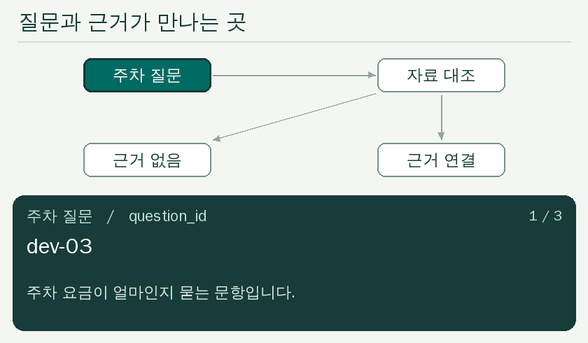

세 문서는 대출 기간·휴관일·반납함을 설명합니다. 주차 요금을 물었을 때 빈 기대 목록을 쓰는 이유는 자료 안에서 금액을 확인할 수 없기 때문입니다.


### 과제 06 · 근거 없는 질문의 기대값

공통 개발 질문 dev-03의 기대 문서 목록과 answerable을 채우세요.


In [6]:
# 질문, 기대 원문 ID 목록, 답변 가능 여부를 적으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>case = {&quot;question_id&quot;: &quot;dev-03&quot;, &quot;question&quot;: &quot;주차 요금은 얼마인가요?&quot;,
        &quot;expected_document_ids&quot;: [], &quot;answerable&quot;: False}
print(case[&quot;expected_document_ids&quot;], case[&quot;answerable&quot;])</code></pre>
<p>실행 결과</p><pre><code>[] False</code></pre>
<p>빈 목록과 False는 지금 가진 자료로 주차 요금을 확인할 수 없다는 뜻입니다. 무료나 0원이라는 답을 나타내지 않습니다.</p>
</details>


### 평가 질문과 기대 문서 ID

<p>question_id는 질문의 이름이고 expected_document_ids는 답을 확인할 원문 ID 목록입니다. 답변 가능 여부는 answerable에 true 또는 false로 적습니다. 근거가 없는 질문은 기대 원문 목록이 비어 있어야 합니다. 정답 문장의 말투보다 어떤 자료로 확인할 수 있는지를 먼저 정합니다.</p>

<p>development의 3문항으로 코드와 기준을 설명하고 holdout의 2문항은 설명 후 같은 규칙이 적용되는지 확인합니다. 공개된 교육용 문항이므로 비공개 시험이나 실제 사용자 성능을 뜻하지 않습니다. 확인 문항을 보며 튜닝했다면 이후에는 새 확인 문항이 필요합니다. 35장에서는 이 구분을 평가 절차로 확장합니다.</p>


## 돌아보기

월요일, 14일, 24시간 중 하나를 골라 자료 이름·쪽·원문 ID를 말해 보세요. 다음 장에 넘길 때는 세 문서의 본문과 ID를 유지하고, 실험으로 잘게 자른 자료는 별도로 식별합니다.

### 문서에서 답변까지

**문서를 읽고 정리**　본문과 원문 위치를 보존합니다.

```
library-1 · 도서 대출 기간은 14일입니다.
```

**질문 관련 문서 선택**　검색 방법은 이후 장에서 구현합니다.

```
질문: 대출 기간은?
선택할 문서: library-1
```

**근거를 입력에 포함**　근거가 없으면 답변을 보류합니다.

```
question + documents → answer
```
